# Pneumonia Detection — Deep Learning Model Comparison

This is a **separate research-comparison notebook**. Keep your existing two-stage notebook for the Gradio app.

Models compared:
- VGG16
- ResNet50
- DenseNet121
- InceptionV3
- MobileNetV2 (deep-learning baseline)

Protocol:
- Train/validation split is made only from the original `train` directory.
- The original `test` directory is kept untouched until final evaluation.
- All models use the same split, image size, metrics, and test set.
- These are transfer-learning classifiers: pretrained backbone + new binary classification head.

**Important:** This is an educational research prototype, not a medical diagnostic tool. Do not interpret model probabilities as medical certainty.


## 1. Mount Google Drive and set dataset path

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

DATA_DIR = Path(
    "/content/drive/MyDrive/AI ML_RESEARCH_PAPER/PNEUMONIA/pneumonia/chest_xray/chest_xray"
)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}\n"
        "Edit DATA_DIR to match your Google Drive folder."
    )

for split in ["train", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        folder = DATA_DIR / split / cls
        if not folder.exists():
            raise FileNotFoundError(f"Missing folder: {folder}")
        count = sum(p.is_file() for p in folder.iterdir())
        print(f"{split}/{cls}: {count} files")


Mounted at /content/drive
train/NORMAL: 1342 files
train/PNEUMONIA: 3892 files
test/NORMAL: 234 files
test/PNEUMONIA: 390 files


## 2. Imports and experiment settings

In [2]:
import os, gc, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16, ResNet50, DenseNet121, InceptionV3, MobileNetV2
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.densenet import preprocess_input as dense_preprocess
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobile_preprocess

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5  # Start with 5; increase after the pipeline works.
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Create one reproducible train/validation split

In [3]:
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

train_paths, train_labels = [], []
for label, cls in enumerate(["NORMAL", "PNEUMONIA"]):
    paths = sorted(
        p for p in (DATA_DIR / "train" / cls).iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )
    train_paths.extend([str(p) for p in paths])
    train_labels.extend([label] * len(paths))

train_paths = np.asarray(train_paths)
train_labels = np.asarray(train_labels, dtype=np.int32)

tr_paths, val_paths, y_train, y_val = train_test_split(
    train_paths, train_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=train_labels
)

test_paths, y_test = [], []
for label, cls in enumerate(["NORMAL", "PNEUMONIA"]):
    paths = sorted(
        p for p in (DATA_DIR / "test" / cls).iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )
    test_paths.extend([str(p) for p in paths])
    y_test.extend([label] * len(paths))

test_paths = np.asarray(test_paths)
y_test = np.asarray(y_test, dtype=np.int32)

print("Train:", len(tr_paths), "Validation:", len(val_paths), "Test:", len(test_paths))
print("Train class counts [NORMAL, PNEUMONIA]:", np.bincount(y_train))
print("Validation class counts:", np.bincount(y_val))
print("Test class counts:", np.bincount(y_test))


Train: 4185 Validation: 1047 Test: 624
Train class counts [NORMAL, PNEUMONIA]: [1073 3112]
Validation class counts: [268 779]
Test class counts: [234 390]


## 4. Build datasets (same split for every model)

In [4]:
def make_dataset(paths, labels, preprocess_fn, training=False):
    paths = paths.astype(str)
    labels = labels.astype(np.float32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load_image(path, label):
        image_bytes = tf.io.read_file(path)
        image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMG_SIZE)
        image = preprocess_fn(image)
        return image, label

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(min(len(paths), 2000), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

# We use class weights because the training data has more PNEUMONIA than NORMAL images.
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
CLASS_WEIGHTS = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", CLASS_WEIGHTS)


Class weights: {0: 1.950139794967381, 1: 0.6723971722365039}


## 5. Define model builders

In [5]:
MODEL_CONFIGS = {
    "VGG16": (VGG16, vgg_preprocess),
    "ResNet50": (ResNet50, resnet_preprocess),
    "DenseNet121": (DenseNet121, dense_preprocess),
    "InceptionV3": (InceptionV3, inception_preprocess),
    "MobileNetV2": (MobileNetV2, mobile_preprocess),
}

def build_transfer_model(model_name):
    backbone_class, preprocess_fn = MODEL_CONFIGS[model_name]
    backbone = backbone_class(
        weights="imagenet",
        include_top=False,
        input_shape=(*IMG_SIZE, 3)
    )
    backbone.trainable = False  # First train only the new classification head.

    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    x = backbone(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = Model(inputs, outputs, name=f"{model_name}_pneumonia")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )
    return model, preprocess_fn


In [6]:
# Train one model at a time and save it immediately to avoid holding all backbones in RAM.
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/AI ML_RESEARCH_PAPER/PNEUMONIA/model_comparison")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

histories = {}
validation_results = []

for model_name, (_, preprocess_fn) in MODEL_CONFIGS.items():
    print("\n" + "=" * 70)
    print("Training:", model_name)
    print("=" * 70)

    tf.keras.backend.clear_session()
    gc.collect()

    model, _ = build_transfer_model(model_name)
    train_ds = make_dataset(tr_paths, y_train, preprocess_fn, training=True)
    val_ds = make_dataset(val_paths, y_val, preprocess_fn, training=False)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_auc", mode="max", patience=2,
            restore_best_weights=True, verbose=1
        )
    ]

    start = time.time()
    history = model.fit(
        train_ds, validation_data=val_ds,
        epochs=EPOCHS, class_weight=CLASS_WEIGHTS,
        callbacks=callbacks, verbose=1
    )
    elapsed = time.time() - start

    val_prob = model.predict(val_ds, verbose=0).ravel()
    val_pred = (val_prob >= 0.5).astype(int)

    validation_results.append({
        "model": model_name,
        "val_accuracy": accuracy_score(y_val, val_pred),
        "val_precision": precision_score(y_val, val_pred, zero_division=0),
        "val_recall": recall_score(y_val, val_pred, zero_division=0),
        "val_f1": f1_score(y_val, val_pred, zero_division=0),
        "val_roc_auc": roc_auc_score(y_val, val_prob),
        "training_seconds": round(elapsed, 1),
        "epochs_ran": len(history.history["loss"])
    })
    histories[model_name] = history.history

    model_path = SAVE_DIR / f"{model_name.lower()}_pneumonia.keras"
    model.save(model_path)
    print("Saved:", model_path)

    del model, train_ds, val_ds
    tf.keras.backend.clear_session()
    gc.collect()

validation_df = pd.DataFrame(validation_results).sort_values("val_roc_auc", ascending=False)
display(validation_df)
validation_df.to_csv(SAVE_DIR / "validation_comparison.csv", index=False)



Training: VGG16
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 324s 1s/step - accuracy: 0.7854 - auc: 0.8648 - loss: 0.6853 - val_accuracy: 0.9169 - val_auc: 0.9699 - val_loss: 0.2364
Epoch 2/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 60s 328ms/step - accuracy: 0.8937 - auc: 0.9559 - loss: 0.3186 - val_accuracy: 0.9417 - val_auc: 0.9828 - val_loss: 0.1737
Epoch 3/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 70s 401ms/step - accuracy: 0.9228 - auc: 0.9717 - loss: 0.2334 - val_accuracy: 0.9532 - val_auc: 0.9864 - val_loss: 0.1422
Epoch 4/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 59s 319ms/step - accuracy: 0.9314 - auc: 0.9787 - loss: 0.1914 - val_accuracy: 0.9417 - val_auc: 0.9881 - val_loss: 0.1513
Epoch 5/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 69s 393ms/step - accuracy: 0.9309 - auc: 0.9804 - loss: 0.1852 - val_accuracy: 0.9561 - val_auc: 0.9900 - val_loss: 0.1227
Restoring model weights from the end of the best epoch: 5.
Saved: /content/drive/MyDrive/AI ML_RESEARCH_PAPER/PNEUMONIA/mode

,model,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,training_seconds,epochs_ran
1,ResNet50,0.971347,0.992116,0.969191,0.980519,0.995862,308.0,5
4,MobileNetV2,0.948424,0.993197,0.937099,0.964333,0.993955,346.0,5
0,VGG16,0.956065,0.985430,0.955071,0.970013,0.990837,582.4,5
2,DenseNet121,0.944604,0.989145,0.935815,0.961741,0.987244,361.9,5
3,InceptionV3,0.935053,0.981055,0.930680,0.955204,0.984562,385.7,5


## 7. Compare validation results

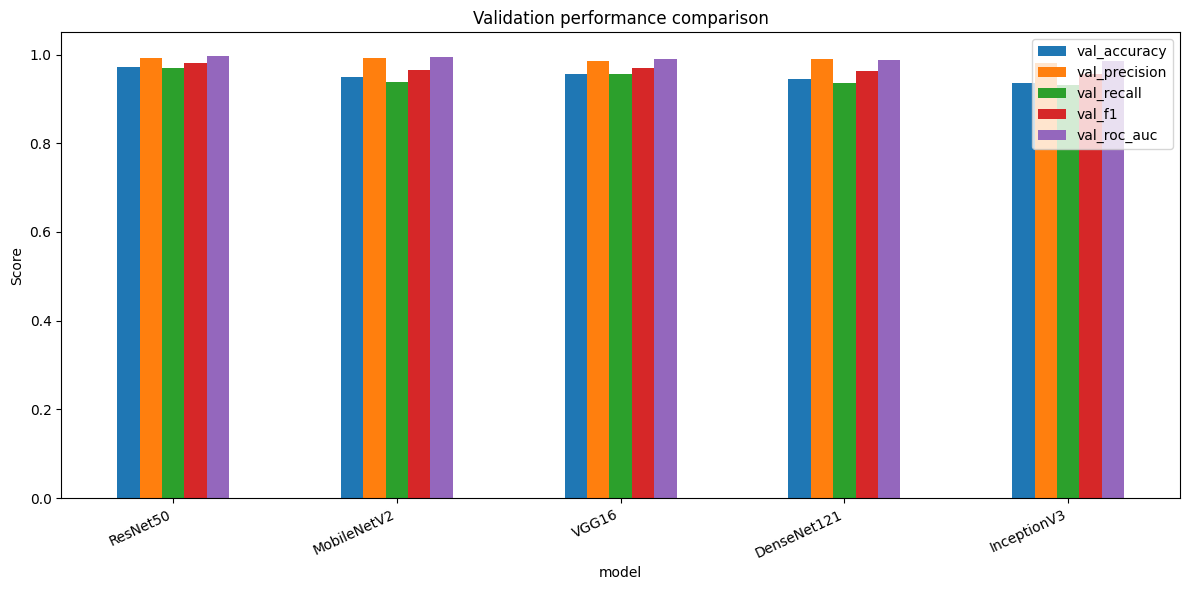

In [7]:
ax = validation_df.set_index("model")[["val_accuracy", "val_precision", "val_recall", "val_f1", "val_roc_auc"]].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1.05)
)
ax.set_ylabel("Score")
ax.set_title("Validation performance comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## Research notes / limitations

- Do not claim one architecture is universally best; report what your experiment actually finds.
- Report test metrics, not only training or validation accuracy. Recall is especially important to discuss for the PNEUMONIA class, while false negatives must be considered carefully.
- The provided `val` directory has very few images, so this notebook creates a stratified validation split from `train`; the original `test` directory is preserved for final evaluation.
- This dataset may have class imbalance and possible dataset-specific biases. Describe the dataset source and split protocol in the paper.
- For a stronger study, repeat experiments with multiple random seeds, report mean ± standard deviation, inspect ROC curves/confusion matrices, and compare parameter count and inference time.
- This is not a clinical validation study and must not be presented as a medical diagnostic system.


## 8. Final evaluation on the untouched test set
Run this after all models have trained. Do not use test results to tune models or thresholds.


In [8]:
test_results = []
test_details = {}

for model_name, (_, preprocess_fn) in MODEL_CONFIGS.items():
    tf.keras.backend.clear_session()
    gc.collect()

    model_path = SAVE_DIR / f"{model_name.lower()}_pneumonia.keras"
    model = tf.keras.models.load_model(model_path)
    test_ds = make_dataset(test_paths, y_test, preprocess_fn, training=False)

    prob = model.predict(test_ds, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)

    test_results.append({
        "model": model_name,
        "test_accuracy": accuracy_score(y_test, pred),
        "test_precision": precision_score(y_test, pred, zero_division=0),
        "test_recall": recall_score(y_test, pred, zero_division=0),
        "test_f1": f1_score(y_test, pred, zero_division=0),
        "test_roc_auc": roc_auc_score(y_test, prob)
    })
    test_details[model_name] = (pred, prob)

    print("\n", model_name)
    print(classification_report(
        y_test, pred, labels=[0, 1],
        target_names=["NORMAL", "PNEUMONIA"],
        zero_division=0
    ))
    print("Confusion matrix [rows=true, columns=predicted]:")
    print(confusion_matrix(y_test, pred))

    del model, test_ds
    tf.keras.backend.clear_session()
    gc.collect()

test_df = pd.DataFrame(test_results).sort_values("test_roc_auc", ascending=False)
display(test_df)
test_df.to_csv(SAVE_DIR / "test_comparison.csv", index=False)



 VGG16
              precision    recall  f1-score   support

      NORMAL       0.93      0.60      0.73       234
   PNEUMONIA       0.80      0.97      0.88       390

    accuracy                           0.83       624
   macro avg       0.87      0.79      0.80       624
weighted avg       0.85      0.83      0.82       624

Confusion matrix [rows=true, columns=predicted]:
[[140  94]
 [ 10 380]]

 ResNet50
              precision    recall  f1-score   support

      NORMAL       0.93      0.54      0.68       234
   PNEUMONIA       0.78      0.98      0.87       390

    accuracy                           0.81       624
   macro avg       0.86      0.76      0.77       624
weighted avg       0.84      0.81      0.80       624

Confusion matrix [rows=true, columns=predicted]:
[[126 108]
 [  9 381]]

 DenseNet121
              precision    recall  f1-score   support

      NORMAL       0.94      0.70      0.80       234
   PNEUMONIA       0.84      0.97      0.90       390

    a

,model,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
4,MobileNetV2,0.875000,0.849776,0.971795,0.906699,0.962163
2,DenseNet121,0.868590,0.842222,0.971795,0.902381,0.956114
1,ResNet50,0.812500,0.779141,0.976923,0.866894,0.953780
0,VGG16,0.833333,0.801688,0.974359,0.879630,0.949003
3,InceptionV3,0.828526,0.801706,0.964103,0.875437,0.927504


## Research notes / limitations
- Do not claim one architecture is universally best; report what this experiment finds.
- Use the untouched test set only for final reporting. Do not select models or tune thresholds based on test results.
- Report PNEUMONIA recall and discuss false negatives, alongside precision, F1 and ROC-AUC.
- The provided `val` folder has very few images, so this notebook creates a stratified validation split from `train`; the original `test` folder is preserved for final evaluation.
- This split is image-level. If multiple images belong to the same patient, patient-level splitting is preferable to avoid leakage.
- For a stronger study, repeat with multiple random seeds and report mean ± standard deviation, and compare parameter count and inference time.
- This is not a clinical validation study and must not be presented as a medical diagnostic tool.
